# Hälsostudie Del 1


## Datakonroll

In [1]:
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns
import os 
import numpy as np 
from pathlib import Path
from matplotlib.ticker import PercentFormatter
from scipy import stats

In [2]:
filnamn = "health_study_dataset.csv"
arbetsmapp = Path.cwd().resolve()

möjliga_filer = [
    mapp / "data" / filnamn
    for mapp in [arbetsmapp, *arbetsmapp.parents]
]

csv_fil = next((fil for fil in möjliga_filer if fil.exists()), None)

if csv_fil is None:
    raise FileNotFoundError(
        f"Hittade inte {filnamn} i någon data-mapp. "
        f"Notebookens arbetsmapp är: {arbetsmapp}"
    )

df = pd.read_csv(csv_fil)

huvudmapp = csv_fil.parent.parent
bilder_mapp = huvudmapp / "bilder"
bilder_mapp.mkdir(exist_ok=True)

print(f"Läste in filen: {csv_fil}")
print(f"Antal rader och kolumner: {df.shape}")
print(f"Bilder sparas i: {bilder_mapp}")

Läste in filen: C:\Users\PC\Desktop\Hälsostudie Del 1\data\health_study_dataset.csv
Antal rader och kolumner: (800, 9)
Bilder sparas i: C:\Users\PC\Desktop\Hälsostudie Del 1\bilder


In [3]:

print("Antal deltagare och variabler:", df.shape)

print("\nSaknade värden:")
print(df.isna().sum())

print("\nAntal dubblettrader:", df.duplicated().sum())

variabler = ["age", "weight", "height", "systolic_bp", "cholesterol"]
print("\nDatatyper:")

print(df[variabler].dtypes)

Antal deltagare och variabler: (800, 9)

Saknade värden:
id             0
age            0
sex            0
height         0
weight         0
systolic_bp    0
cholesterol    0
smoker         0
disease        0
dtype: int64

Antal dubblettrader: 0

Datatyper:
age              int64
weight         float64
height         float64
systolic_bp    float64
cholesterol    float64
dtype: object


## Beskrivande analys
Ålder, vikt, längd, systoliskt blodtryck och kolesterol sammanfattas med medelvärde, median, minimi- och maximivärde. Det ger en bild av datans nivå och spridning. 

In [4]:

variabler = ["age", "weight", "height", "systolic_bp", "cholesterol"]

sammanfattning = df[variabler].agg(["mean", "median", "min", "max"]).T

sammanfattning = sammanfattning.rename(
    index={
        "age": "Ålder (år)",
        "weight": "Vikt (kg)",
        "height": "Längd (cm)",
        "systolic_bp": "Systoliskt blodtryck (mmHg)",
        "cholesterol": "Kolesterol (mmol/L)",
    },
    columns={
        "mean": "Medelvärde",
        "median": "Median",
        "min": "Min",
        "max": "Max",
    },
)

sammanfattning.round(2)

,Medelvärde,Median,Min,Max
Ålder (år),49.43,50.00,18.0,90.00
Vikt (kg),73.41,73.20,33.7,114.40
Längd (cm),171.85,171.35,144.4,200.40
Systoliskt blodtryck (mmHg),149.18,149.40,106.8,185.90
Kolesterol (mmol/L),4.93,4.97,2.5,7.88


För alla fem variabler ligger medelvärde och median nära varandra, vilket tyder på ganska jämna och symmetriska fördelningar. Medelvärdet för systoliskt blodtryck
är 149,18 mmHg och medianen är 149,40 mmHg. Deltagarans ålder sträcker sig från 18 till 90 år, med ett medelvärde på 49,43 år. 
Minimi- och maximivärdena ser rimliga ut, och ingen uppenbara felaktiga värden syns i tabellen. 

## Grafer 
Graferna hjälper oss att se hur värdena är fördelade och jämför grupper. De visar blodtryckens fördelning, vikt per kön och andelen rökare. 

## 1. Histogram över systoliskt blodtryck

Ett histogram delar in blodtrycksvärdena i intervall. Stapelhöjden visar hur många deltagare som har värden i varje intervall. 

I diagrammet syns också: 
- **Den böjda linjen** visar fördelnings form, alltså var värdena ligger tätast. 
- **Den streckade linjen** markerar medelvärdet, 149,2 mmHg. 
- **Det gula området** markerar det centrala området, 135-167 mmHg.


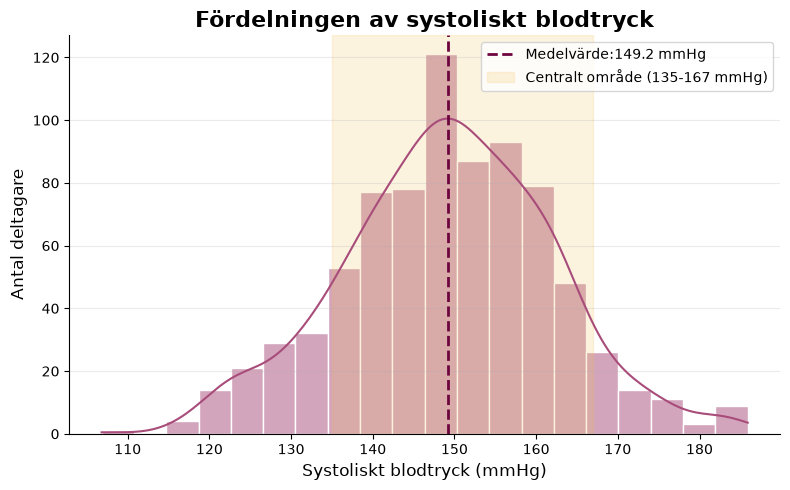

In [5]:
plt.figure(figsize=(8,5))
sns.histplot(
    data=df, 
    x="systolic_bp", 
    bins=20, 
    kde=True,
    color="#A84C7A",
    edgecolor="white",
    linewidth=1
)

medel=df["systolic_bp"].mean()
plt.axvline(medel, color="#6E043F", linestyle="--", linewidth=2,
            label=f"Medelvärde:{medel:.1f} mmHg")

plt.axvspan(135, 167, color="#F2C14E", alpha=0.18,
            label="Centralt område (135-167 mmHg)")

plt.title("Fördelningen av systoliskt blodtryck", fontsize=16, weight="bold")
plt.xlabel("Systoliskt blodtryck (mmHg)", fontsize=12)
plt.ylabel("Antal deltagare", fontsize=12)
plt.legend()
plt.grid(axis="y", alpha=0.25)
sns.despine()
plt.tight_layout()

plt.savefig(bilder_mapp / "blodtryck_histogram.png", dpi=150, bbox_inches="tight")
plt.show()

Histogramet visar att deltagarnas systoliska blodtryck främst är koncentrerat kring 150mmHg. De flesta observationerna ligger ungefär mellan 135 och 167 mmHg, medan det finns färre deltagare med lägre och högre värden. Medelvärdet är cirka 149,2 mmHg. Detta beskriver fördelningen i det här datasetet. 

## Boxplot över vikt per kön 

Boxploten visar hur vikten fördelar sig i varje grupp.
- **Strecket i lådan** är medianen, alltså mittvärdet. 
- **Lådan** innehållet de mittersta 50% av deltagarna. 
- **Strecken ut från lådan** visar ungefär hur långt de vanliga värdena sträcker sig. 
- **De grå prickarna** visar varje enskild deltagare, Där prickarna ligger tätt finns många deltagare. 
- **De turkosa prickarna** är extremvärden, alltså ovanligt höga eller låga värden jämfört med resten av gruppen.


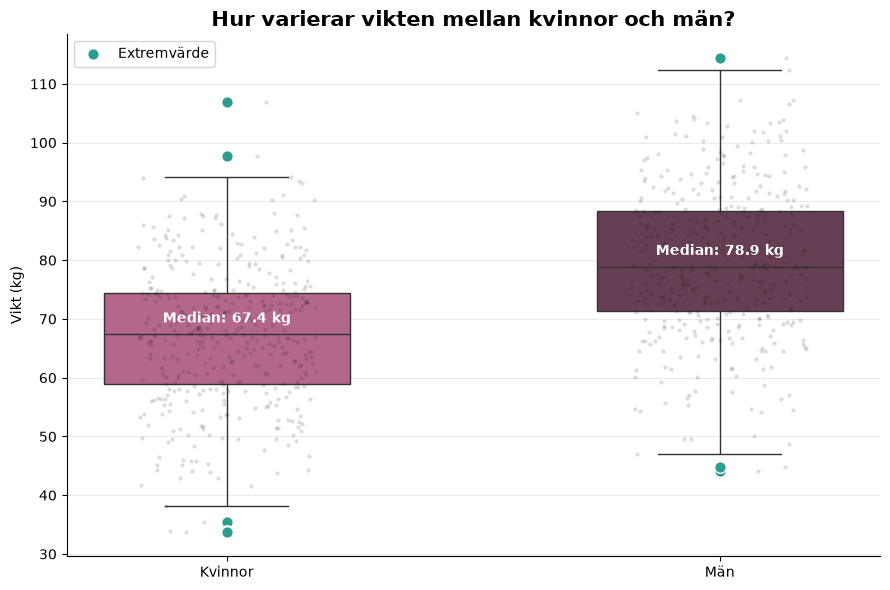

In [6]:
df["kön_namn"] = df["sex"].map({"F": "Kvinnor", "M": "Män"})
ordning = ["Kvinnor", "Män"]

fig, ax = plt.subplots(figsize=(9, 6))

sns.boxplot(
    data=df,
    x="kön_namn",
    y="weight",
    hue="kön_namn",
    order=ordning,
    palette=["#C05A8A", "#6E3856"],
    width=0.5,
    showfliers=False,
    ax=ax
)

sns.stripplot(
    data=df,
    x="kön_namn",
    y="weight",
    order=ordning,
    color="#1B1A1A",
    alpha=0.15,
    size=3,
    jitter=0.18,
    ax=ax
)

def hitta_extremvärden(serie):
    q1 = serie.quantile(0.25)
    q3 = serie.quantile(0.75)
    iqr = q3 - q1
    return serie[(serie < q1 - 1.5 * iqr) | (serie > q3 + 1.5 * iqr)]

medianer = df.groupby("kön_namn")["weight"].median()

for position, grupp in enumerate(ordning):
    värden = df[df["kön_namn"] == grupp]["weight"]
    extrema = hitta_extremvärden(värden)

    ax.scatter(
        np.full(len(extrema), position),
        extrema,
        color="#2A9D8F",
        edgecolor="white",
        linewidth=1,
        s=70,
        zorder=5,
        label="Extremvärde" if position == 0 else None
    )

    ax.text(
        position,
        medianer[grupp] + 2,
        f"Median: {medianer[grupp]:.1f} kg",
        ha="center",
        fontsize=10,
        weight="bold",
        color="white",
        zorder=6
    )

ax.set_title("Hur varierar vikten mellan kvinnor och män?", fontsize=15, weight="bold")
ax.set_xlabel("")
ax.set_ylabel("Vikt (kg)")
ax.grid(axis="y", alpha=0.25)
ax.legend(loc="upper left")

sns.despine()
plt.tight_layout()

plt.savefig(bilder_mapp / "vikt_boxplot.png", dpi=150, bbox_inches="tight")
plt.show()

Medianvikten är högre bland män än bland kvinnor i datasetet. Samtidigt varierar vikterna inom båda grupperna och överlappar, så diagrammet visar inte att varje man väger mer än varje kvinna. Diagrammet beskriver bara deltagarna i den här studien och visar inte vad som orsakar skillnaden. 

## 3. Stapeldiagram över andelen rökare

Först beräknas andelen som svaret "Yes" respektive "No". Med `normalize=True` görs antalet om till andelar, och multiplikation med 
100 ger procent.

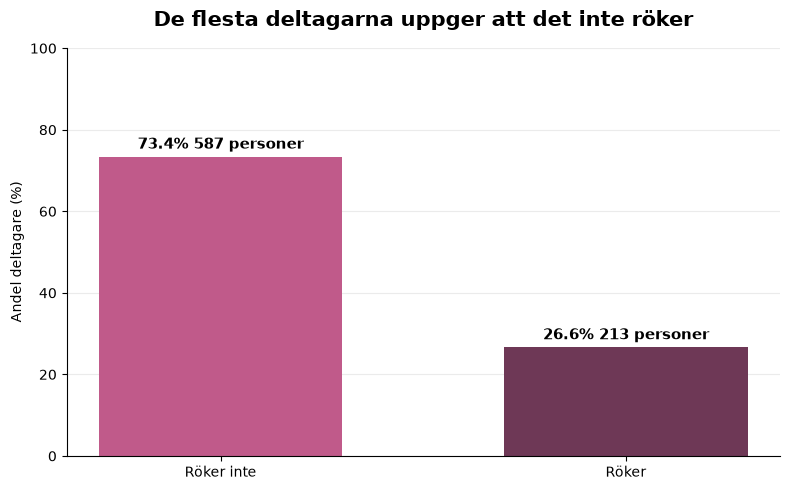

In [7]:
antal = df["smoker"]. value_counts().reindex(["No", "Yes"], fill_value=0)
procent = antal / antal.sum() * 100

namn = ["Röker inte", "Röker"]
färger =["#C05A8A", "#6E3856"]

fig, ax = plt.subplots(figsize=(8, 5))

staplar = ax.bar(
    namn,
    procent,
    color=färger,
    width=0.6
)

for stapel, pct, n in zip(staplar, procent, antal):
    ax.text(
        stapel.get_x() + stapel.get_width() / 2,
        stapel.get_height() + 2,
        f"{pct:.1f}% {n} personer",
        ha="center",
        fontsize=11,
        weight="bold" 
    )

ax.set_title("De flesta deltagarna uppger att det inte röker",
             fontsize=15, weight="bold", pad=16)
ax.set_ylabel("Andel deltagare (%)")
ax.set_ylim(0, 100)
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(bilder_mapp / "antal_stapeldiagram.png", dpi=150, bbox_inches="tight")

plt.show()


Diagrammet visar att ungefär tre fjärdedelar av deltagarna uppger att de inte röker, medan ungefär en fjärdedel uppger att de röker. 
Procentsatserna gäller deltagarna i datasetet.

## Simulering av sjudomsandel

Först beräknas andelen deltagare med sjukdomen i datasetet. Den andelen används sedan som sannolikhet när datorn skapar 1000 slumpade personer. Ett fast random seed (till exempel `default_rng(42)`) gör att slumpen blir densamma varje gång koden körs, så att resultatet går att återskapa. 

In [8]:
verklig_andel = (df["disease"] == 1). mean()

np.random.seed(42)

simulerade_personer = np.random.binomial(
    n=1,
    p=verklig_andel,
    size=1000
)

simulerad_andel = simulerade_personer.mean()

print(f"Verklig andel i datasetet: {verklig_andel:.1%}")
print(f"Simulerad andel bland 1000 personer: {simulerad_andel:.1%}")
print(f"Skillnad: {abs(simulerad_andel - verklig_andel):.1%}")

Verklig andel i datasetet: 5.9%
Simulerad andel bland 1000 personer: 5.6%
Skillnad: 0.3%


I datasetet hade 5,9 % av deltagarna sjukdomen. I simuleringen av 1000 slumpade personer blev andelen 5,6%,
vilket är en skillnad på 0,3 procentenheter. Simuleringen hamnade alltså nära datamängdens andel. 
Den lilla skillnaden beror på slumpen. 

## Konfidensintervall för systoliskt blodtryck 

Ett 95%-igt konfidensintervall för medelvärdet beräknas med en normalapproximation. Intervallet visar var det verkliga medelvärdet troligen ligger. 
Metoden utgår från stickprovets medelvärde och standardfel, som visar hur mycket medelvärdet kan variera av en slump. 


In [9]:
blodtryck = df["systolic_bp"].dropna()

n = len(blodtryck)
medel = blodtryck.mean()
standardavvikelse = blodtryck.std(ddof=1)

standardfel = standardavvikelse / np.sqrt(n)

nedre_gräns = medel - 1.96 * standardfel 
övre_gräns = medel + 1.96 * standardfel 

print(f"Antal deltagare: {n}")
print(f"Medelvärde: {medel:.2f} mmHg")
print(f"95 % konfidensintervall: {nedre_gräns:.2f}--{övre_gräns:.2f}mmHg")



Antal deltagare: 800
Medelvärde: 149.18 mmHg
95 % konfidensintervall: 148.29--150.07mmHg


Medelblodtrycket bland de 800 deltagarna är 149,18 mmHg. Det 95% konfidensintervall är 148,29 - 150,07 mmHg.
Intervallet visar hur säkert medelvärdet är uppskattat. Ju smalare intervall, desto säkrare uppskattning. 
Det gäller genomsnittet, inte blodtrycket hos varje enskild deltagare. 


## Hypotesprövning

Welch t-test används för att jämföra blodtrycket hos rökare och icke-rökare. Testet passar för att jämföra två gruppers medelvärden och kräver, till skillnad från det klassiska t-testet, inte att grupperna har samma spridning. Ett ensidigt test valdes eftersom hypotesen gäller en bestämd riktning: att rökare har högre blodtryck.



In [10]:
rökare = df.loc[df["smoker"] == "Yes", "systolic_bp"].dropna()
icke_rökare = df.loc[df["smoker"] == "No", "systolic_bp"].dropna()

resultat = stats.ttest_ind(
    rökare,
    icke_rökare,
    equal_var=False,
    alternative="greater"
)

print(f"Antal rökare: {len(rökare)}")
print(f"Antal icke-rökare: {len(icke_rökare)}")
print(f"Medelblodtryck för rökare: {rökare.mean():.2f} mmHg")
print(f"Medelblodtryck för icke_rökare: {icke_rökare.mean():.2f} mmHg")
print(f"t-värde: {resultat.statistic:.3f}")
print(f"p-värde: {resultat.pvalue:.4f}")

Antal rökare: 213
Antal icke-rökare: 587
Medelblodtryck för rökare: 149.52 mmHg
Medelblodtryck för icke_rökare: 149.05 mmHg
t-värde: 0.450
p-värde: 0.3264


Rökarnas medelblodtryck var 149,52 mmHg, jämfört med 149,05 mmHg för icke-rökare. Skillnaden var liten (0,47 mmHg). Welch t-testet gav p = 0,3264,
vilket är större än 0,05. Därför finns det inte tillräckligt statistikt stöd för att säga att rökare har högre medelblodtryck i detta dataset. 
Resultatet visar inte att rökning orsakar blodtrycksskillnad. 



## VG

## Konfidensintervall med bootstrap

et 95 %-igt konfidensintervall för medelvärdet av systoliskt blodtryck beräknades med bootstrap. Metoden drar nya stickprov ur den egna datan och visar hur mycket
medelvärdet varierar av en slump. 

Såhär gick det till: 
1. Stickprov lika stora som orginalet drogs slumpmässigt mer återläggning, alltså att samma person kan dras fler gånger. 
2. Medelvärdet beräknades för varje stickprov. Detta upprepades 10 000 gånger. 
3. De 2,5 % lägsta och de 2.5 % högsta medelvärdena togs bort. De mittersta 95 % utgör konfidensintervallet. 

Bootstrap valdes som komplement till normalapproximationen eftersom metoden inte kräver att datan är normalfördelad. Ett fast seed (`default_rng(42)`) gör att resultatet kan återskapas. Slumpdragningarna gjordes med  `numpy.random.Generator.choice` (NumPy-dokumentationen: https://numpy.org/doc/stable/reference/random/generated/numpy.random.Generator.choice.html)


In [11]:
rng = np.random.default_rng(42)

antal_omdragningar = 10_000

bootstrap_stickprov = rng.choice(
    blodtryck,
    size=(antal_omdragningar, len(blodtryck)),
    replace=True
)

bootstrap_medelvärden = bootstrap_stickprov.mean(axis=1)

bootstrap_nedre = np.percentile(bootstrap_medelvärden, 2.5)
bootstrap_övre = np.percentile(bootstrap_medelvärden, 97.5)

print(f"Normalapproximation: {nedre_gräns:.2f}--{övre_gräns:.2f} mmHg")
print(f"Bootstrap:           {bootstrap_nedre:.2f}--{bootstrap_övre:.2f} mmHg")



Normalapproximation: 148.29--150.07 mmHg
Bootstrap:           148.31--150.05 mmHg


## Jämförelse av de två metoderna

Formeln (normalapproximationen) gav intervallet 148.29 - 150.07 mmHg
Bootstrap gav intervallet 148.31 - 150.05 mmHg.

Intervallen är nästan lika, vilket betyder att formeln fungerar bra för denna data. 

Det verkliga medelvärdet för systoliskt blodtryck troligen ligger mellan cirka 148,3 och 150,1 mmHg. 

## Power-simulering för hypotestestet 

Power är sannolikheten att testet upptäcker en skillnad som verkligen finns. Simulering undersöker hur ofta Welchs t-test (ensidigt, `alternative="greater"`) hittar en skillnad i medelblodtryck mellan rökare och icke-rökare, för olika tänkta skillnader mellan 0 och 5 mmHg.

Målnivån för power är 80%, vilket är en vanlig tumregel. Testet utförs med `scipy.stats.ttest_ind` (SciPy-dokumentationen: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html) och slumpdragningar med `numpy.random.Generator.choice` (NumPy-dokumentationen: https://numpy.org/doc/stable/reference/random/generated/numpy.random.Generator.choice.html).

In [ ]:
rng = np.random.default_rng(42)

tänkta_skillnader = [0, 0.5, 1, 1.5, 2, 2.5, 3, 3.5, 4, 5]
antal_simuleringar = 1000
alpha = 0.05

power_lista = []

for skillnad in tänkta_skillnader:
    träffar = 0

    for _ in range(antal_simuleringar):
        sim_icke_rökare = rng.choice( 
            icke_rökare,
            size=len(icke_rökare),
            replace=True
        )

        sim_rökare = rng.choice(
            rökare,
            size=len(rökare),
            replace=True
        )

        sim_rökare = (
            sim_rökare
            - rökare.mean()
            + icke_rökare.mean()
            + skillnad
        )

        test = stats.ttest_ind(
            sim_rökare,
            sim_icke_rökare,
            equal_var=False,
            alternative="greater"
        )

        if test.pvalue < alpha:
            träffar += 1

    power = träffar / antal_simuleringar
    power_lista.append(power)
    print(f"Tänkt skillnad {skillnad} mmHg: power = {power:.1%}")

Tänkt skillnad 0 mmHg: power = 4.7%
Tänkt skillnad 0.5 mmHg: power = 13.6%
Tänkt skillnad 1 mmHg: power = 24.5%
Tänkt skillnad 1.5 mmHg: power = 41.3%
Tänkt skillnad 2 mmHg: power = 61.0%
Tänkt skillnad 2.5 mmHg: power = 76.4%
Tänkt skillnad 3 mmHg: power = 88.0%
Tänkt skillnad 3.5 mmHg: power = 96.4%
Tänkt skillnad 4 mmHg: power = 98.7%
Tänkt skillnad 5 mmHg: power = 100.0%


 Power-simulering visar hur bra testet är på att hitta skillnader i blodtryck mellan rökare och icke-röckare. Datorn upprepade testet 1000 gånger för olika tänkta skillnader. Resultatet visar att testet ofta hittar stora skillnader, men ofta missar små. Det hjälper att förstå testets begränsningar. Det säger inte att de tänkta skillnaderna faktiskt finns i datan.

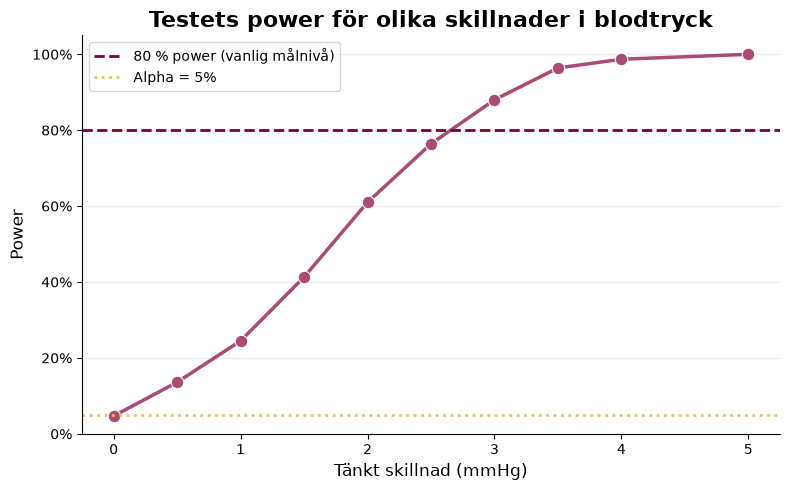

In [ ]:
plt.figure(figsize=(8, 5))

sns.lineplot(
    x=tänkta_skillnader,
    y=power_lista,
    marker="o",
    markersize=9,
    color="#A84c75",
    linewidth=2.5
)

plt.axhline(0.8, color="#6e043F", linestyle="--", linewidth=2, label="80 % power (vanlig målnivå)")
plt.axhline(alpha, color="#F2C14E", linestyle=":", linewidth=2, label=f"Alpha = {alpha:.0%}")

ax= plt.gca()
ax.yaxis.set_major_formatter(PercentFormatter(1.0))

plt.title("Testets power för olika skillnader i blodtryck", fontsize=16, weight="bold")
plt.xlabel("Tänkt skillnad (mmHg)", fontsize=12)
plt.ylabel("Power", fontsize=12)
plt.ylim(0, 1.05)
plt.legend()
plt.grid(axis="y", alpha=0.25)
sns.despine()
plt.tight_layout()

os.makedirs("bilder", exist_ok=True)
plt.savefig(bilder_mapp / "power_diagram.png", dpi=150, bbox_inches="tight")
plt.show()

### Vilken skillnad ger minst 80 % power?

Power visar hur ofta testet upptäcker en skillnad som verkligen finns. Här används 80 % som målnivå, vilket är ett vanligt riktvärde.
Koden samlar resultaten från simuleringen i en tabell och letar sedan upp den minsta testade skillnaden i blodtryck som når minst 
80 % power. 

In [14]:
resultat = pd.DataFrame({
    "skillnad_mmHg": tänkta_skillnader,
    "power": power_lista
})

print(resultat)

nådde_80 = resultat[resultat["power"]>=0.8]

if not nådde_80.empty:
    första = nådde_80.iloc[0]
    print(f"\nMinsta skillnad med minst 80% power: {första['skillnad_mmHg']} mmHg")
else:
    print("\nIngen av de testade skillnaderna nådde 80% power.")

   skillnad_mmHg  power
0            0.0  0.047
1            0.5  0.136
2            1.0  0.245
3            1.5  0.413
4            2.0  0.610
5            2.5  0.764
6            3.0  0.880
7            3.5  0.964
8            4.0  0.987
9            5.0  1.000

Minsta skillnad med minst 80% power: 3.0 mmHg


### Vad resultatet visar 

Testet når 80 % power först vid en skillnad på 3,0 mmHg (power= 88,0 %). Vid 2,5 mmhg är power 76,4 %, alltså strax under målnivå. 

Det betyder att: 
- Skillnader på 3.0 mmhg eller mer upptäcks i det flesta fall med det här urvalet. 
- Mindre skillnader riskera att missas. Vid 1,0 mmHg upptäcks skillnaden bara i 24,5 % av simuleringen. 
- Ett resultat utan signifikant skillnaden ska därför tolkas försiktigt om den verkliga skillnaden kan vara liten. 